# Recursive feature elimination on handwritten digits

Rank the 64 pixels in scikit-learn's handwritten digits dataset. Both pipelines scale the pixels to [0, 1], fit default logistic regression and eliminate one pixel at a time until one remains. Rank 1 marks the retained pixel.

Moxie uses `LogisticRegressionImportance` to expose the native classifier's coefficients to RFE. It uses `FeatureCount` to distinguish integer counts from fractions and retrieves the fitted selector with the typed `step[1]()` accessor.

Adapted from the scikit-learn developers' [digits RFE gallery example](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/feature_selection/plot_rfe_digits.py) (BSD-3-Clause).

In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import sklearn
from sklearn.datasets import load_digits
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks/_support/moxie_nb.py").exists())
oracle = ROOT / "families/ensemble/builds/oracle-env"
receipt = ROOT / "families/ensemble/docs/private/forest_engine/oracle-build.json"
if oracle not in Path(sklearn.__file__).resolve().parents:
    raise RuntimeError("Use the pinned oracle environment described in docs/feature_selection/classifier-selection.md")
assert json.loads(receipt.read_text())["revision"] == "4358542a1bd39af2e7e1cbace8b9fed067473c5b"

sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_selection/plot_rfe_digits")

digits = load_digits()
X = digits.data
y = digits.target.astype(np.int64)
reference = Pipeline([
    ("scaler", MinMaxScaler()),
    ("rfe", RFE(LogisticRegression(), n_features_to_select=1, step=1)),
]).fit(X, y)

nb.share(X=X, y=y)

In [2]:
%%mojo rfe
from moxie.feature_selection import FeatureCount, LogisticRegressionImportance, RFE
from moxie.linear_model import LogisticRegression
from moxie.pipeline import Pipeline
from moxie.preprocessing import MinMaxScaler
from moxie_nb_io import load, save, save_ints


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var selector = RFE(
        LogisticRegressionImportance(LogisticRegression()),
        n_features_to_select=FeatureCount(1),
        step=FeatureCount(1),
    )
    var pipeline = Pipeline(MinMaxScaler(), selector^)
    _ = pipeline.fit(X, y)

    ref fitted = pipeline.step[1]()
    save_ints("ranking", fitted.ranking_())
    save_ints("selected_indices", fitted.get_support(True)[List[Int]])
    save("transformed", pipeline.transform(X))
    save("predictions", pipeline.predict(X))

In [3]:
mx = nb.results["rfe"]
selected = reference.named_steps["rfe"]
nb.compare("pixel rankings", selected.ranking_, mx["ranking"], exact=True)
nb.compare("retained pixel", selected.get_support(indices=True), mx["selected_indices"], exact=True)
nb.compare("scaled retained pixel", reference.transform(X), mx["transformed"], exact=True)
nb.compare("refitted predictions", reference.predict(X), mx["predictions"], exact=True)
assert mx["predictions"].dtype == np.int64
assert mx["transformed"].dtype == np.float64

nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
pixel rankings,PASS,"(64,)","(64,)",,,exact,0 mismatches,
retained pixel,PASS,"(1,)","(1,)",,,exact,0 mismatches,
scaled retained pixel,PASS,"(1797, 1)","(1797, 1)",,,exact,0 mismatches,
refitted predictions,PASS,"(1797,)","(1797,)",,,exact,0 mismatches,


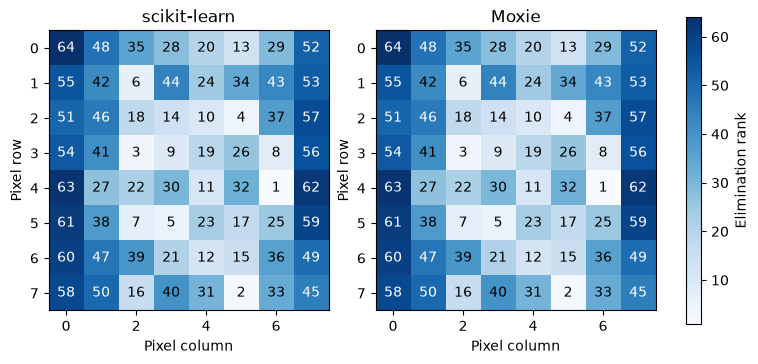

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.5), layout="constrained")
for ax, title, rankings in zip(
    axes, ("scikit-learn", "Moxie"), (selected.ranking_, mx["ranking"])
):
    ranks = rankings.reshape(digits.images.shape[1:])
    image = ax.imshow(ranks, cmap="Blues", vmin=1, vmax=X.shape[1])
    ax.set(title=title, xlabel="Pixel column", ylabel="Pixel row")
    for (row, column), rank in np.ndenumerate(ranks):
        color = "white" if rank > 42 else "black"
        ax.text(column, row, str(rank), ha="center", va="center", color=color)
fig.colorbar(image, ax=axes, label="Elimination rank")
plt.show()